<a href="https://colab.research.google.com/github/kareemkhaleel695-hub/suxkl-next-instagram-pinterest/blob/main/Customer_Churn_Phase_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the IBM Telco Customer Churn dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Check for missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
# Check for duplicate rows and customer IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [8]:
# Check for blank values in TotalCharges
blank_values = df["TotalCharges"].astype(str).str.strip().eq("")

print("Blank values:", blank_values.sum())

df.loc[blank_values, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank values: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [9]:
# Generate descriptive statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Check for invalid numerical values

total_charges_numeric = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Invalid TotalCharges:",
      total_charges_numeric.isnull().sum())

print("Negative tenure:",
      (df["tenure"] < 0).sum())

print("Negative MonthlyCharges:",
      (df["MonthlyCharges"] < 0).sum())

print("Negative TotalCharges:",
      (total_charges_numeric < 0).sum())

Invalid TotalCharges: 11
Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0


In [11]:
# Investigate customers with missing TotalCharges

df.loc[total_charges_numeric.isna(),
       ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [12]:
# Check tenure of affected customers

df.loc[total_charges_numeric.isna(), "tenure"].value_counts()

,count
tenure,
0,11


In [13]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

In [14]:
# Handle missing TotalCharges for new customers
df.loc[
    (df["tenure"] == 0) & (df["TotalCharges"].isna()),
    "TotalCharges"
] = 0

In [15]:
# Verify data quality after cleaning

print("Missing values:", df["TotalCharges"].isna().sum())
print("Data type:", df["TotalCharges"].dtype)
print("Dataset shape:", df.shape)

Missing values: 0
Data type: float64
Dataset shape: (7043, 21)


In [16]:
# Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

print("Training set:", train_df.shape)
print("Testing set:", test_df.shape)

Training set: (5634, 21)
Testing set: (1409, 21)


In [17]:
# Verify class distribution after splitting

print("Training distribution:")
print(train_df["Churn"].value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(test_df["Churn"].value_counts(normalize=True) * 100)

Training distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


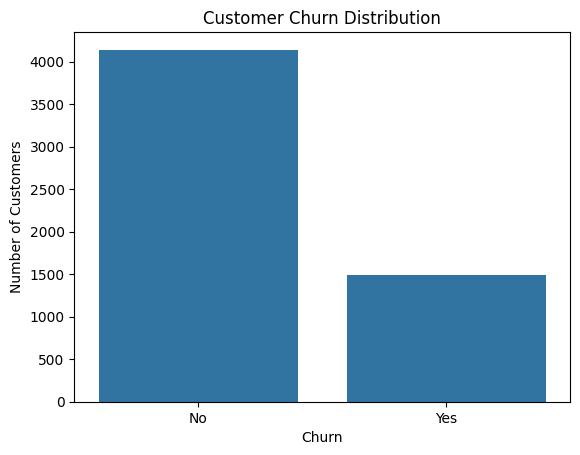

In [18]:
# Visualize churn distribution in training data

sns.countplot(data=train_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

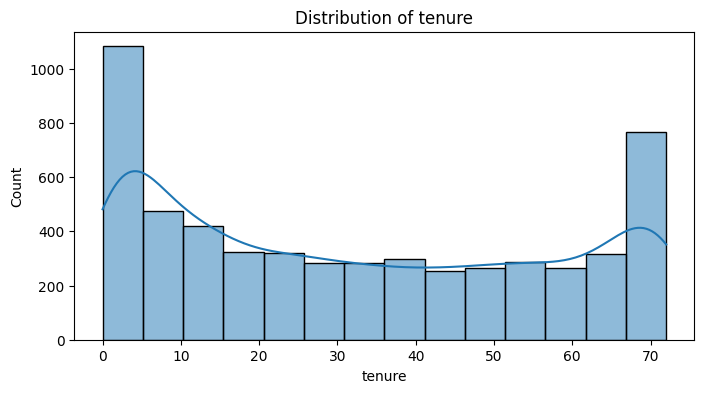

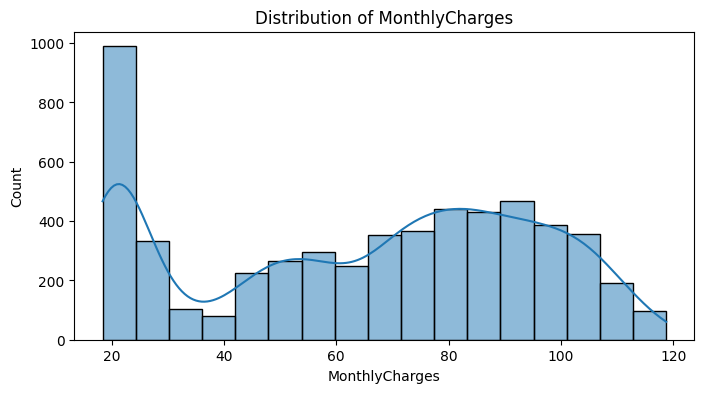

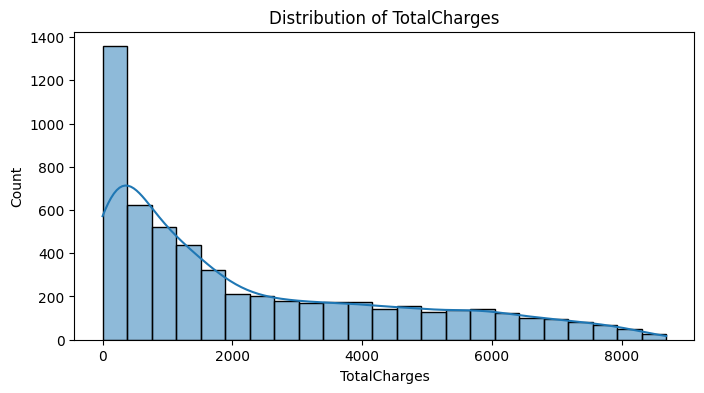

In [19]:
# Analyze numerical feature distributions

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for feature in numerical_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=train_df, x=feature, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.show()

In [24]:
# Compare numerical features by churn status

train_df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.59,61.34,2564.72
Yes,18.36,74.86,1564.59


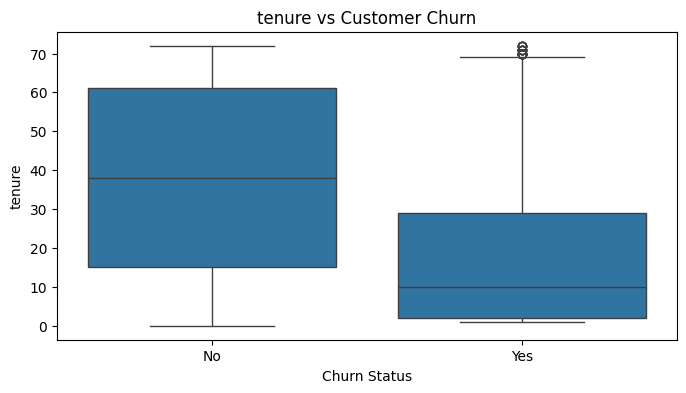

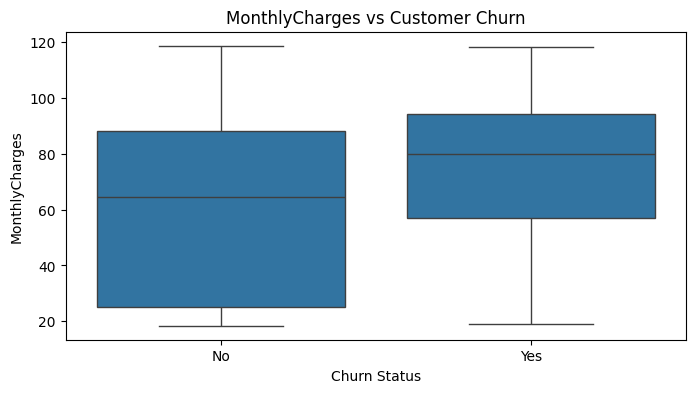

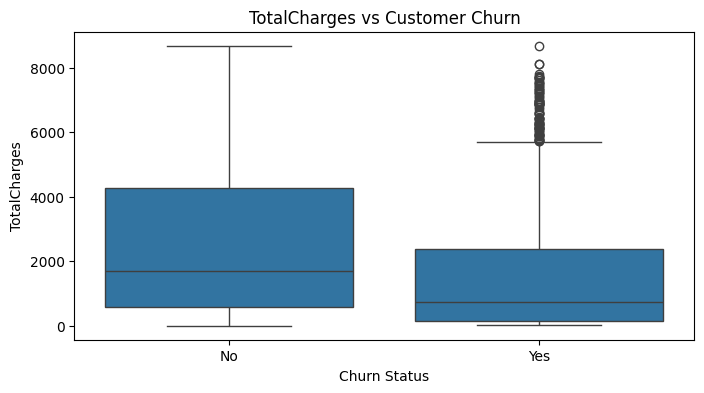

In [25]:
# Compare numerical features between churn groups

for feature in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=train_df,
        x="Churn",
        y=feature
    )

    plt.title(f"{feature} vs Customer Churn")
    plt.xlabel("Churn Status")
    plt.ylabel(feature)

    plt.show()

In [26]:
# Analyze churn rates by categorical features

categorical_features = [
    "Contract",
    "InternetService",
    "TechSupport"
]

for feature in categorical_features:
    print(f"\n{feature} Churn Rate (%)")

    churn_rate = (
        train_df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
    )

    print(churn_rate)


Contract Churn Rate (%)
Contract
Month-to-month    42.75
One year          11.08
Two year           2.87
Name: Churn, dtype: float64

InternetService Churn Rate (%)
InternetService
DSL            18.69
Fiber optic    42.09
No              7.25
Name: Churn, dtype: float64

TechSupport Churn Rate (%)
TechSupport
No                     41.75
No internet service     7.25
Yes                    15.16
Name: Churn, dtype: float64


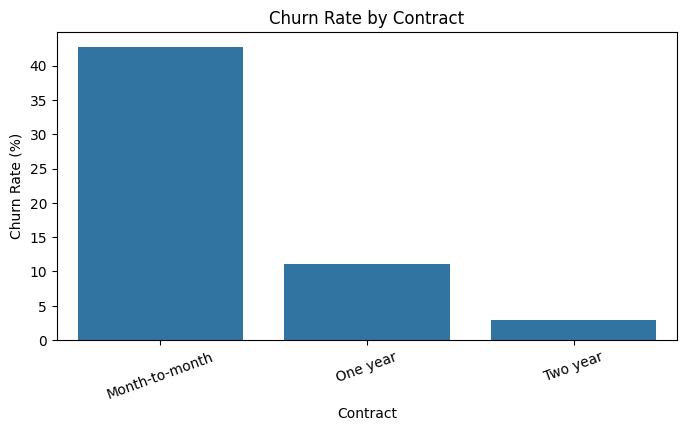

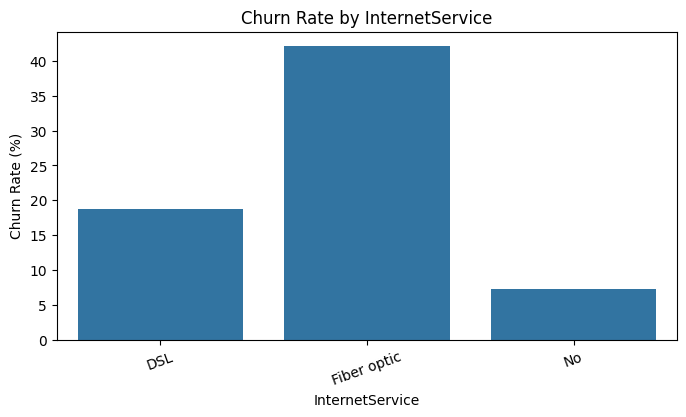

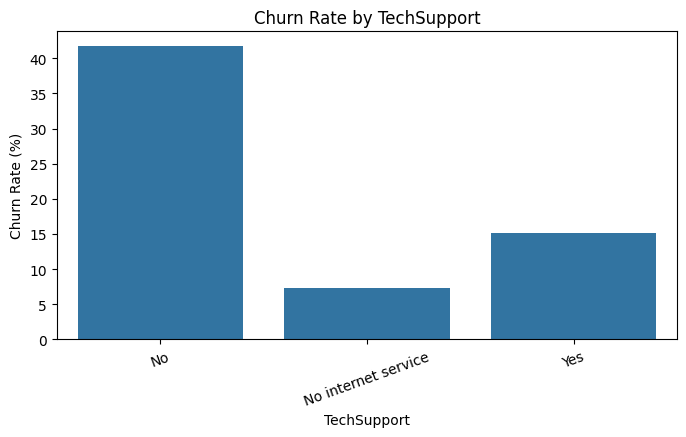

In [27]:
# Visualize churn rate by categorical features

for feature in categorical_features:

    churn_rate = (
        train_df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="ChurnRate")
    )

    plt.figure(figsize=(8, 4))

    sns.barplot(
        data=churn_rate,
        x=feature,
        y="ChurnRate"
    )

    plt.title(f"Churn Rate by {feature}")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=20)
    plt.show()

In [28]:
# Separate features and target

X_train = train_df.drop(
    columns=["Churn", "customerID"]
)

y_train = train_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

X_test = test_df.drop(
    columns=["Churn", "customerID"]
)

y_test = test_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Identify numerical and categorical features

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training shape:", X_train.shape)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training shape: (5634, 19)


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [30]:
# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [31]:
# Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [33]:
# Combine numerical and categorical pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup'

In [34]:
# Fit preprocessing on training data only

X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without refitting
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (5634, 45)
Testing shape: (1409, 45)


In [35]:
# Check original and processed dataset shapes

print("Original Training:", X_train.shape)
print("Processed Training:", X_train_processed.shape)

print("Original Testing:", X_test.shape)
print("Processed Testing:", X_test_processed.shape)

Original Training: (5634, 19)
Processed Training: (5634, 45)
Original Testing: (1409, 19)
Processed Testing: (1409, 45)


In [36]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nProcessed feature names:")
for feature in feature_names:
    print(feature)

Total processed features: 45

Processed feature names:
num__SeniorCitizen
num__tenure
num__MonthlyCharges
num__TotalCharges
cat__gender_Female
cat__gender_Male
cat__Partner_No
cat__Partner_Yes
cat__Dependents_No
cat__Dependents_Yes
cat__PhoneService_No
cat__PhoneService_Yes
cat__MultipleLines_No
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_DSL
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No
cat__StreamingMovies_No internet service
cat__StreamingMovies_Yes
cat__Contract_Month-to-month
cat__Contract_One year
cat

In [37]:
# Verify that processed data has no missing values

import numpy as np

train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

test_array = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("Training missing values:", np.isnan(train_array).sum())
print("Testing missing values:", np.isnan(test_array).sum())

print("All training values finite:", np.isfinite(train_array).all())
print("All testing values finite:", np.isfinite(test_array).all())

Training missing values: 0
Testing missing values: 0
All training values finite: True
All testing values finite: True


In [38]:
# Check scaling results for numerical features

numeric_output = preprocessor.named_transformers_["num"].transform(X_train[numeric_features])

print("Means:", np.round(numeric_output.mean(axis=0), 2))
print("Standard deviations:", np.round(numeric_output.std(axis=0), 2))

Means: [ 0. -0. -0.  0.]
Standard deviations: [1. 1. 1. 1.]


In [39]:
# Save preprocessing pipeline

import joblib

joblib.dump(preprocessor, "preprocessing_pipeline.joblib")

print("Preprocessing pipeline saved successfully!")

Preprocessing pipeline saved successfully!


In [40]:
# Phase 1 - Final Verification

import numpy as np

print("=== DATASET ===")
print("Total records:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())

print("\n=== DATA SPLIT ===")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\n=== PREPROCESSING ===")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Train missing:",
      np.isnan(train_array).sum())
print("Test missing:",
      np.isnan(test_array).sum())

print("Train finite:",
      np.isfinite(train_array).all())
print("Test finite:",
      np.isfinite(test_array).all())

print("\n=== TARGET DISTRIBUTION ===")
print(y_train.value_counts(normalize=True).round(4))
print(y_test.value_counts(normalize=True).round(4))

=== DATASET ===
Total records: 7043
Duplicate rows: 0
Duplicate customer IDs: 0
Missing values: 0

=== DATA SPLIT ===
Training records: 5634
Testing records: 1409

=== PREPROCESSING ===
Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)
Train missing: 0
Test missing: 0
Train finite: True
Test finite: True

=== TARGET DISTRIBUTION ===
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


In [41]:
# Final churn relationship summary

features = ["Contract", "InternetService", "TechSupport"]

for feature in features:
    print(f"\n{feature}")

    print(
        train_df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
    )

print("\nNumerical feature means by churn:")
print(
    train_df.groupby("Churn")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean().round(2)
)


Contract
Contract
Month-to-month    42.75
One year          11.08
Two year           2.87
Name: Churn, dtype: float64

InternetService
InternetService
DSL            18.69
Fiber optic    42.09
No              7.25
Name: Churn, dtype: float64

TechSupport
TechSupport
No                     41.75
No internet service     7.25
Yes                    15.16
Name: Churn, dtype: float64

Numerical feature means by churn:
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.59           61.34       2564.72
Yes     18.36           74.86       1564.59


In [42]:
import joblib

joblib.dump(
    preprocessor,
    "preprocessing_pipeline.joblib"
)

print("Pipeline saved successfully!")


Pipeline saved successfully!
